
# Unsupervised Learning with Scikit-learn
**ML Month · SOAI Béjaïa workshop**: clustering and dimensionality reduction, hands-on.

### How to use this notebook
- Each section introduces a core concept of unsupervised learning step-by-step.
- Run the cells **from top to bottom**. Later cells reuse variables created earlier.
- Every step has a short *Why?* note to help you build intuition for real-world application.
- Look for the **Your turn** cells to practice yourself!

| Section | What you will do |
|---|---|
| **1. The Pipeline & Scaling** | Why preprocessing and scaling are critical first steps |
| **2. K-Means Clustering** | Group similar points together and find centroids |
| **3. K-Means with Scaling** | See how scaling completely changes clustering results |
| **4. Choosing K (Elbow Method)** | Find the optimal number of clusters using inertia |
| **5. Hierarchical Clustering** | Build tree-like clusters and read Dendrograms |
| **6. Principal Component Analysis (PCA)** | Project high-dimensional data into 2D while preserving variance |
| **7. t-SNE** | Map complex manifolds to 2D for beautiful cluster visualizations |
```

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Setup styling
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.3})
print("Setup done! Ready for Unsupervised Learning.")

Setup done! Ready for Unsupervised Learning.


---
## 1. The Pipeline: Why Scaling Matters First

In unsupervised learning, we do not have a target `y`. We only have features `X`. Most unsupervised algorithms rely on calculating **geometric distances** between data points.

**The data:** We generate a synthetic dataset where one feature (Income in $) has a much larger scale than another (Age in years).

In [25]:
rng = np.random.default_rng(42)
n = 200

age = rng.normal(40, 10, n)
income = rng.normal(50000, 15000, n)

df = pd.DataFrame({"Age": age, "Income": income})
df.head()

,Age,Income
0,43.047171,55063.618232
1,29.600159,71112.227920
2,47.504512,51358.773604
3,49.405647,59659.081899
4,20.489648,19247.418485



### Step 1: Scale the Data
**Why?** If we do not scale, a difference of $10,000 in income will completely overwhelm a difference of 10 years in age when calculating distances.

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

df_scaled = pd.DataFrame(X_scaled, columns=["Age_scaled", "Income_scaled"])
display(df_scaled.head())

,Age_scaled,Income_scaled
0,0.380991,0.312204
1,-1.147555,1.364276
2,0.887666,0.069332
3,1.103771,0.613461
4,-2.183164,-2.035738


---
## 2. K-Means Clustering

**Key idea:** Group data into $K$ clusters by minimizing the distance between points and their assigned cluster centroid.

Let's generate clear clusters first to understand how K-Means works visually.

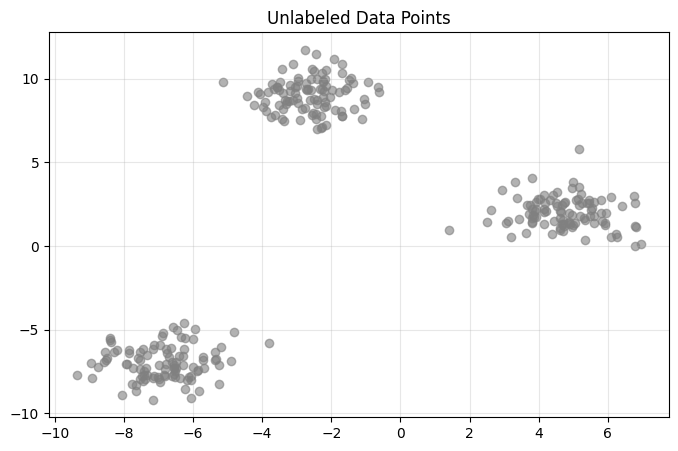

In [27]:
X_blobs, y_true = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Visualize raw data before clustering
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c='gray', alpha=0.6)
plt.title("Unlabeled Data Points")
plt.show()


### Step 2: Initialize and Fit K-Means
**Why?** We initialize the model with the chosen number of clusters ($K=3$), fit it, and assign each point to a cluster.

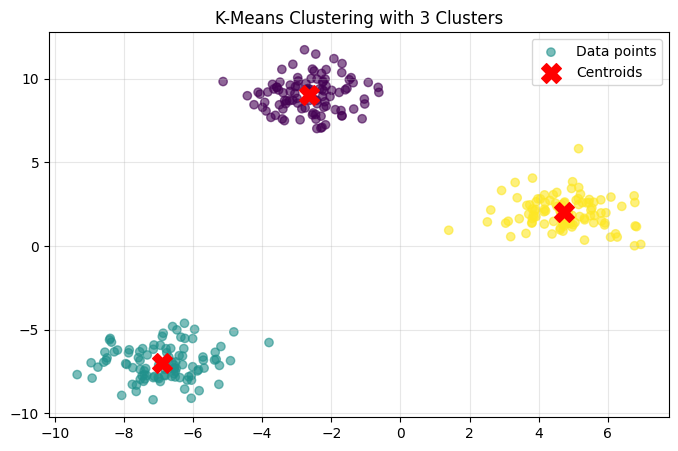

In [28]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_blobs)

# Get cluster predictions and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

# Plot the results
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='viridis', alpha=0.6, label='Data points')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title("K-Means Clustering with 3 Clusters")
plt.legend()

plt.show()

---
## 3. K-Means with vs without Scaling

Let's see what happens to K-Means if we run it on the unscaled Age vs Income data we created in Section 1.

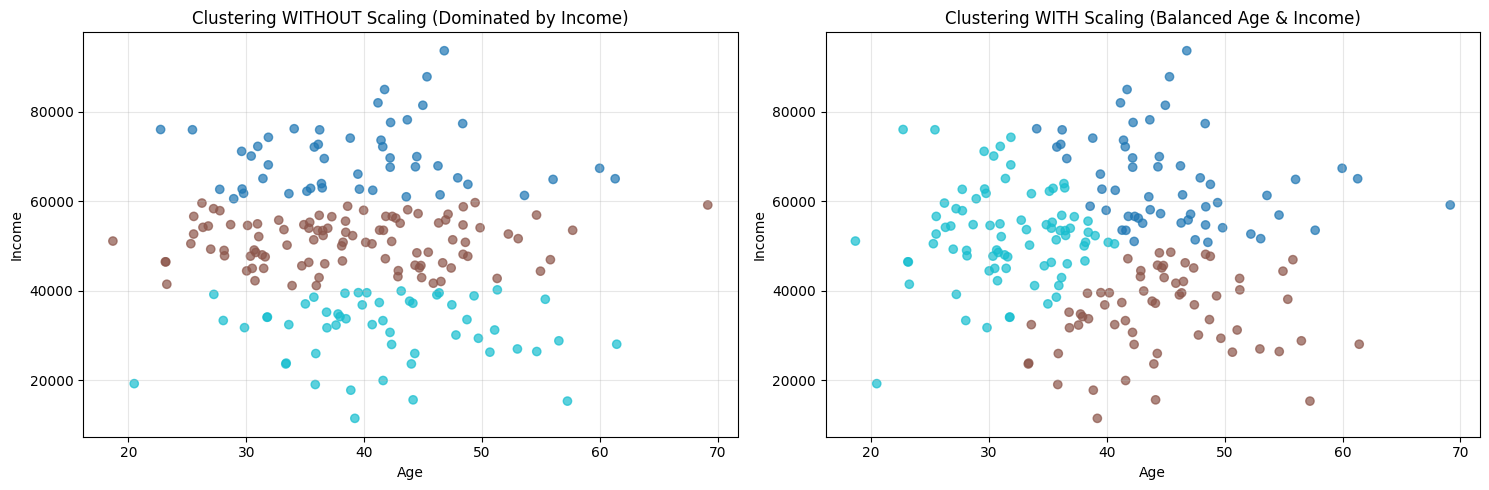

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. K-Means on RAW (unscaled) data
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(df)

# Plotting comparison
ax1.scatter(df['Age'], df['Income'], c=kmeans_raw.labels_, cmap='tab10', alpha=0.7)
ax1.set_title("Clustering WITHOUT Scaling (Dominated by Income)")
ax1.set_xlabel("Age")
ax1.set_ylabel("Income")

# 2. K-Means on SCALED data
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(df_scaled)
ax2.scatter(df['Age'], df['Income'], c=kmeans_scaled.labels_, cmap='tab10', alpha=0.7)
ax2.set_title("Clustering WITH Scaling (Balanced Age & Income)")
ax2.set_xlabel("Age")
ax2.set_ylabel("Income")
plt.tight_layout()
plt.show()

# Your Turn :
Notice how without scaling, the boundary lines are completely horizontal (meaning age is entirely ignored). With scaling, age plays an equal role in forming the clusters.

---
## 4. Choosing K: The Elbow Method

How do we know how many clusters are actually in our data when we cannot easily plot it?

- **Inertia:** The sum of squared distances of samples to their closest cluster center.
- **Elbow Rule:** Plot Inertia for different values of $K$. Look for the "elbow" where the rate of decrease drops sharply.

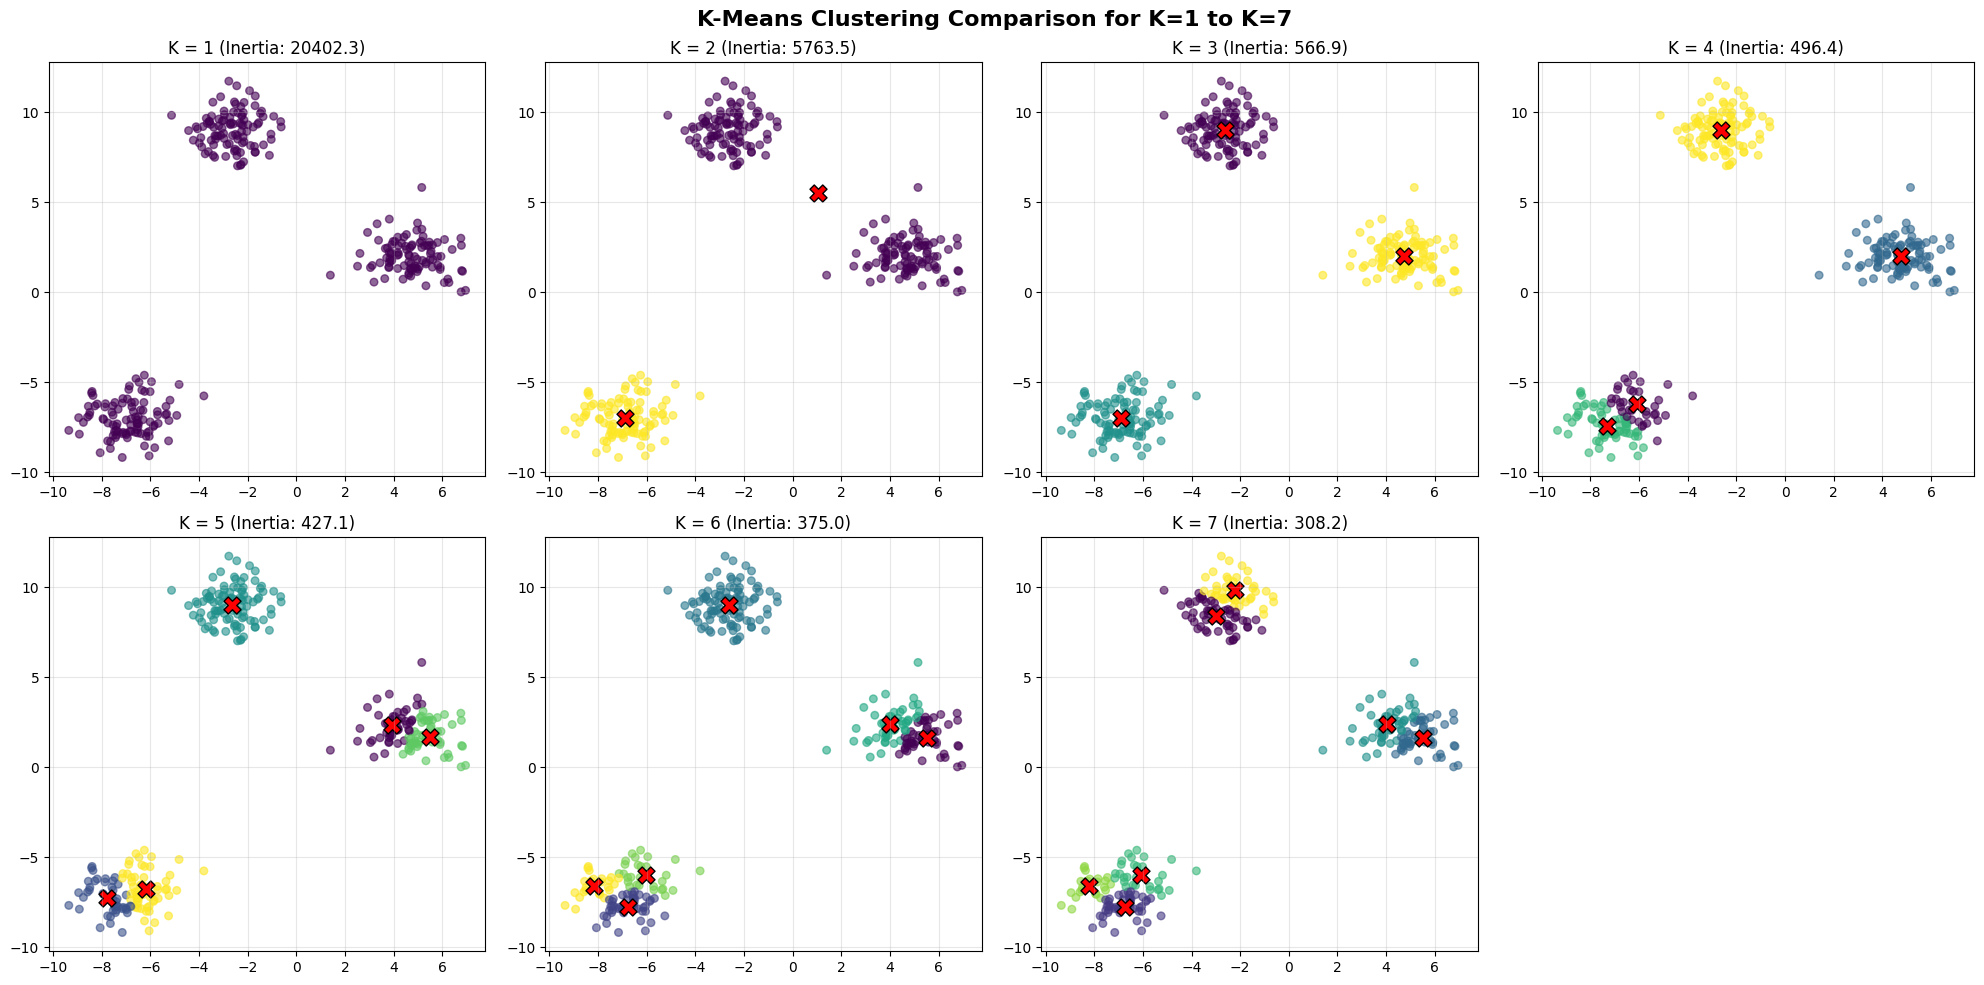

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for k in range(1, 8):
    # Fit K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_blobs)
    centroids = km.cluster_centers_

    # Plot points
    axes[k-1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=km_labels, cmap='viridis', alpha=0.6, s=30)
    # Plot centroids (if K > 1)
    if k > 1:
        axes[k-1].scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=150, edgecolor='black', label='Centroids')

    axes[k-1].set_title(f"K = {k} (Inertia: {km.inertia_:.1f})")
    axes[k-1].grid(True, alpha=0.3)

# Hide the 8th unused subplot
axes[7].axis('off')

plt.suptitle("K-Means Clustering Comparison for K=1 to K=7", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

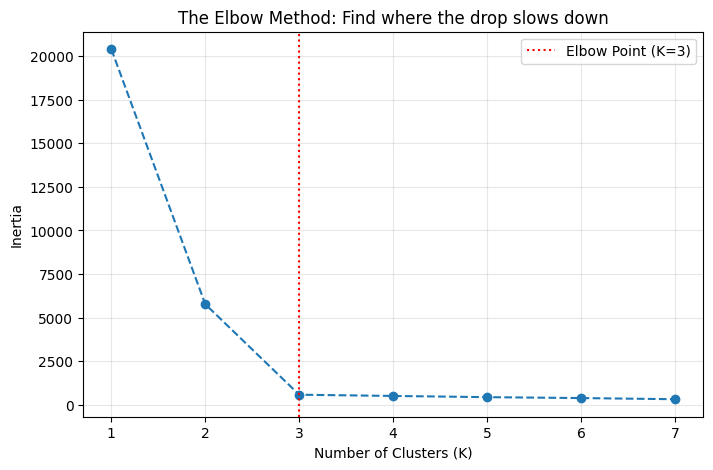

In [31]:
inertias = []
K_range = range(1, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_blobs)
    inertias.append(km.inertia_)

plt.plot(K_range, inertias, marker='o', ls='--')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("The Elbow Method: Find where the drop slows down")
plt.axvline(3, color='red', linestyle=':', label='Elbow Point (K=3)')
plt.legend()
plt.show()

# Silhouette Score

In [32]:
from sklearn.metrics import silhouette_score

# Fit K-Means with K=3
kmeans_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_k3 = kmeans_k3.fit_predict(X_blobs)

# Calculate silhouette score
score_k3 = silhouette_score(X_blobs, labels_k3)
print(f"Silhouette Score for K=3: {score_k3:.4f}")

Silhouette Score for K=3: 0.8480


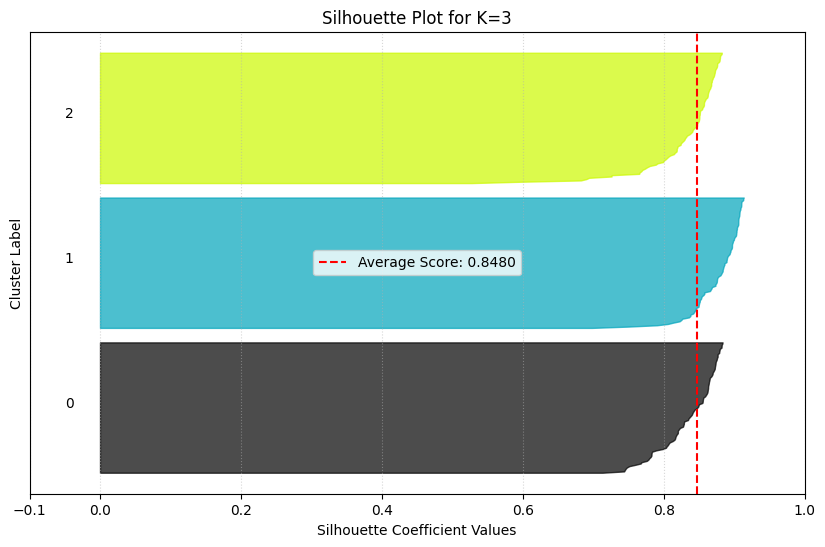

In [33]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

# Calculate individual silhouette values
sample_silhouette_values = silhouette_samples(X_blobs, labels_k3)

fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 10

for i in range(3):
    # Aggregate and sort silhouette values for the cluster
    ith_cluster_sil_vals = sample_silhouette_values[labels_k3 == i]
    ith_cluster_sil_vals.sort()

    size_cluster_i = ith_cluster_sil_vals.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 3)
    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0, ith_cluster_sil_vals,
                     facecolor=color, edgecolor=color, alpha=0.7)

    # Label the silhouette plots with their cluster numbers at the middle
    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10  # 10 for the 0 samples noise

ax.set_title("Silhouette Plot for K=3")
ax.set_xlabel("Silhouette Coefficient Values")
ax.set_ylabel("Cluster Label")

# The vertical line for average silhouette score of all the values
ax.axvline(x=score_k3, color="red", linestyle="--", label=f"Average Score: {score_k3:.4f}")
ax.set_yticks([])  # Clear the yaxis labels / ticks
ax.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
ax.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

---
## 5. Hierarchical Clustering

Instead of pre-defining $K$, hierarchical clustering builds a tree-like hierarchy of clusters.

- **Dendrogram:** A visualization tool showing how points are iteratively linked together.

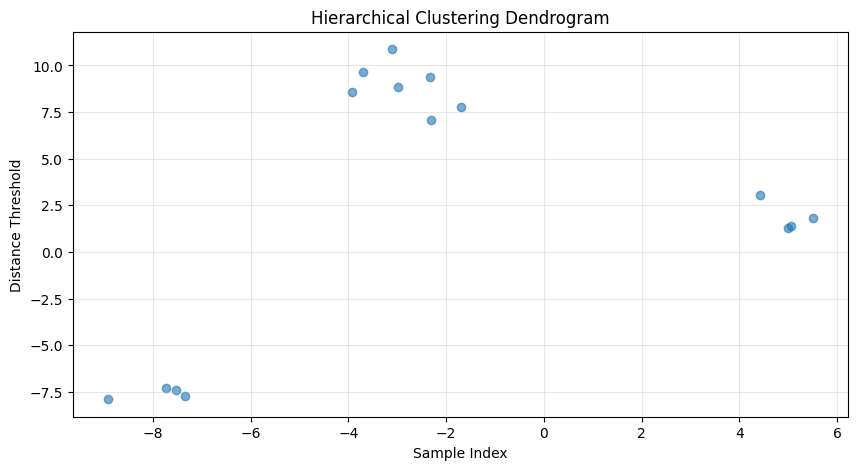

In [42]:
# We take a small sample subset so the Dendrogram is easy to read
sample_data = X_blobs[:15]

plt.figure(figsize=(10, 5))
plt.scatter(sample_data[:, 0], sample_data[:, 1], alpha=0.6)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Distance Threshold")
plt.show()

### Dendrogram

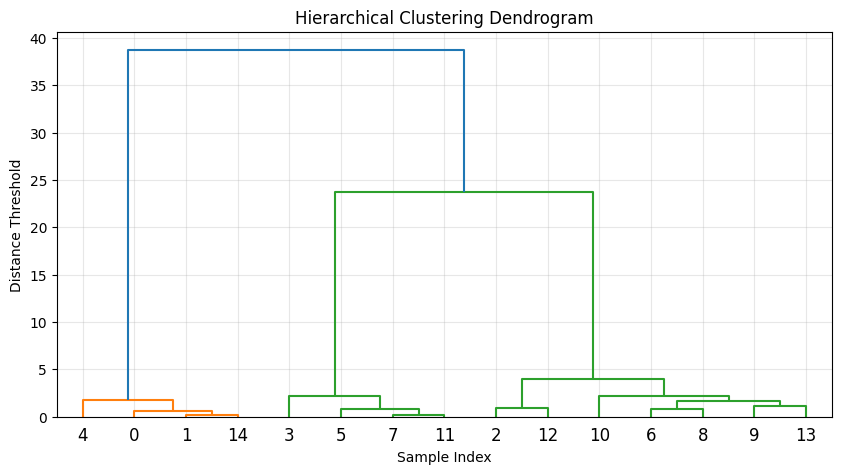

In [35]:

# Linkage matrix
Z = linkage(sample_data, method='ward')

# Plot the Dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Distance Threshold")
plt.show()

---
## 7. t-SNE (t-Distributed Stochastic Neighbor Embedding)

**Key idea:** Unlike PCA (which works linearly), t-SNE is a non-linear method designed specifically to preserve **local structures** (keeping neighbors close in low dimensions).

Let's compare the projection with t-SNE on the same dataset.

In [40]:
from sklearn.datasets import load_digits

# 1. Load the 64-pixel per image dataset (digits dataset)
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

In [47]:
X_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [48]:
df_digits = pd.DataFrame(X_digits)
df_digits.head()

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


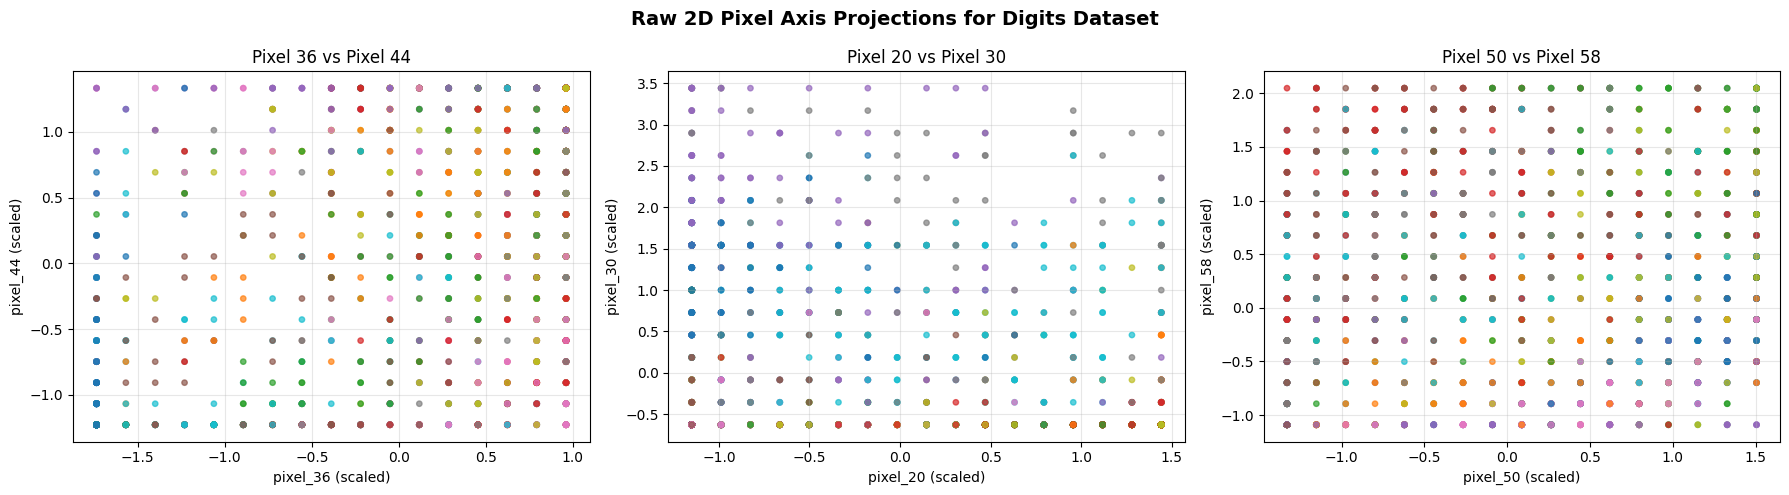

In [49]:
# 1. Create a DataFrame for the Digits dataset and display the head
df_digits = pd.DataFrame(X_digits, columns=[f"pixel_{i}" for i in range(X_digits.shape[1])])


# 2. Plot several raw pixel pairs against each other
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pixel pair 1: Pixel 36 vs Pixel 44
axes[0].scatter(X_digits_scaled[:, 36], X_digits_scaled[:, 44], c=y_digits, cmap='tab10', alpha=0.7, s=15)
axes[0].set_xlabel("pixel_36 (scaled)")
axes[0].set_ylabel("pixel_44 (scaled)")
axes[0].set_title("Pixel 36 vs Pixel 44")

# Pixel pair 2: Pixel 20 vs Pixel 30
axes[1].scatter(X_digits_scaled[:, 20], X_digits_scaled[:, 30], c=y_digits, cmap='tab10', alpha=0.7, s=15)
axes[1].set_xlabel("pixel_20 (scaled)")
axes[1].set_ylabel("pixel_30 (scaled)")
axes[1].set_title("Pixel 20 vs Pixel 30")

# Pixel pair 3: Pixel 50 vs Pixel 58
axes[2].scatter(X_digits_scaled[:, 50], X_digits_scaled[:, 58], c=y_digits, cmap='tab10', alpha=0.7, s=15)
axes[2].set_xlabel("pixel_50 (scaled)")
axes[2].set_ylabel("pixel_58 (scaled)")
axes[2].set_title("Pixel 50 vs Pixel 58")

plt.suptitle("Raw 2D Pixel Axis Projections for Digits Dataset", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

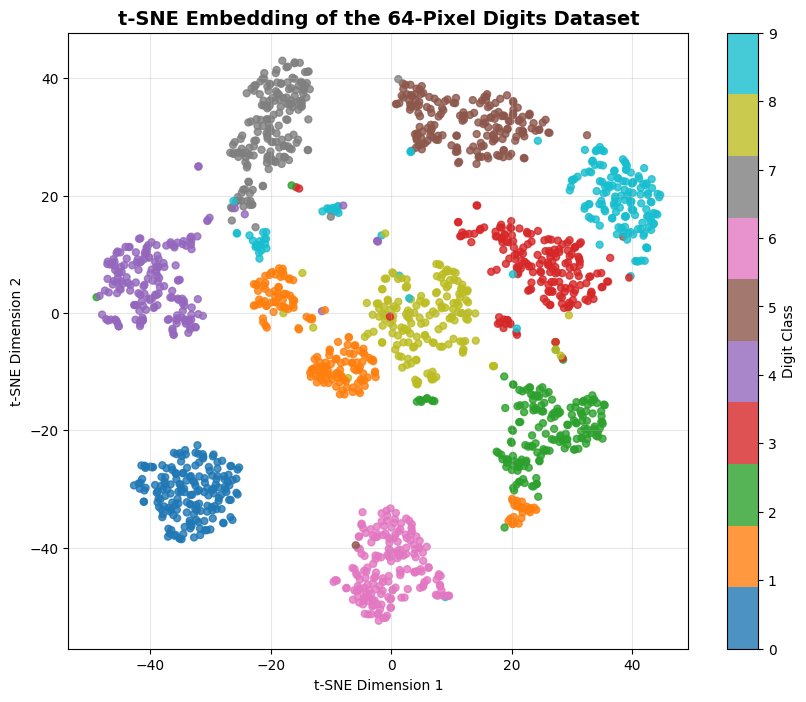

In [46]:


# 2. Scale the features
X_digits_scaled = StandardScaler().fit_transform(X_digits)

# 3. Compute t-SNE on the 64-dimensional data
tsne_digits = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_digits_tsne = tsne_digits.fit_transform(X_digits_scaled)

# 4. Plot the results
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1], c=y_digits, cmap='tab10', alpha=0.8, s=25)
plt.colorbar(scatter, label='Digit Class')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE Embedding of the 64-Pixel Digits Dataset", fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()


**Your Turn:** Notice how t-SNE groups the clusters with a clearer spatial margin compared to PCA! It is an amazing tool for visualizing deep structures in complex datasets.

---
## 6. Principal Component Analysis (PCA)

**Key idea:** Project high-dimensional data into fewer dimensions while keeping as much variance (information) as possible.

Let's load a high-dimensional featureset (Breast Cancer dataset with 30 columns) and project it down to 2 dimensions.

In [ ]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target


In [44]:
# Scale the data first
X_cancer_scaled = StandardScaler().fit_transform(X_cancer)

# 1. Plot the raw data on several 2D feature coordinate pairs first
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Selected pair 1: Mean Radius vs Mean Texture
axes[0].scatter(X_cancer_scaled[:, 0], X_cancer_scaled[:, 1],c=y_cancer, cmap='coolwarm', alpha=0.6)
axes[0].set_xlabel("mean radius (scaled)")
axes[0].set_ylabel("mean texture (scaled)")
axes[0].set_title("Raw Pair 1: Radius vs Texture")

# Selected pair 2: Mean Smoothness vs Mean Concavity
axes[1].scatter(X_cancer_scaled[:, 4], X_cancer_scaled[:, 6], c=y_cancer, cmap='coolwarm', alpha=0.6)
axes[1].set_xlabel("mean smoothness (scaled)")
axes[1].set_ylabel("mean concavity (scaled)")
axes[1].set_title("Raw Pair 2: Smoothness vs Concavity")

# Selected pair 3: Mean Symmetry vs Mean Fractal Dimension
axes[2].scatter(X_cancer_scaled[:, 8], X_cancer_scaled[:, 9],c=y_cancer, cmap='coolwarm',  alpha=0.6)
axes[2].set_xlabel("mean symmetry (scaled)")
axes[2].set_ylabel("fractal dimension (scaled)")
axes[2].set_title("Raw Pair 3: Symmetry vs Fractal Dim")

plt.suptitle("Step 1: Raw 2D Feature Axes (Arbitrary Projections)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

NameError: name 'X_cancer' is not defined

In [43]:
# 2. Fit PCA to find the axes with the absolute highest variance projection
pca = PCA()
X_pca_all = pca.fit_transform(X_cancer_scaled)

# Explain individual variance of top components
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_2d_var = var_pc1 + var_pc2

# 3. Plot the optimal projection using the best two principal components
plt.figure(figsize=(9, 6))
plt.scatter(X_pca_all[:, 0], X_pca_all[:, 1],c=y_cancer, cmap='coolwarm', alpha=0.7, edgecolors='k', linewidths=0.5)
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance)", fontsize=11, fontweight='bold')
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance)", fontsize=11, fontweight='bold')
plt.title(f"Step 2: Optimal PCA Projection\n(Captures {total_2d_var:.1f}% of Total Multidimensional Variance)", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'X_cancer_scaled' is not defined